In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# # These are some parameters to make figures nice (and big)
# params = {'legend.fontsize': 'x-large',
#          'axes.labelsize': 'x-large',
#          'axes.titlesize': 'x-large',
#          'xtick.labelsize': 'x-large',
#          'ytick.labelsize': 'x-large'}

# plt.rcParams.update(params)

plt.style.use('seaborn-v0_8-talk')


# Preprocess 1 Plots

In [2]:
misr_data_file = '../dev/CAMP2Ex_RF17_MISR_OBS_001.nc'

In [3]:
def plot_misr_data(filename, fig, ax, vmax=0.8, cbar_loc='right'):
    misr_data = xr.load_dataset(filename)
    brf = misr_data.brf.data
    for i in range(brf.shape[0]):
        c = ax[i].imshow(brf[i,:,:], cmap='gray', vmin=0, vmax=vmax, aspect='equal')
        ax[i].set_xticks([])
        ax[i].set_yticks([])
        ax[i].set_title('{}\nVZA={:.1f}\nVAA={:.1f}'.format(misr_data.camera.data[i], misr_data.VZA_center.data[i], misr_data.VAA_center.data[i]))
    if(cbar_loc != None):
        plt.colorbar(c, ax=ax[:], shrink=0.7, location=cbar_loc)
    fig.suptitle('Registered to Ellipsoid')

def plot_misr_data_map(filename, fig, ax, vmax=0.5, cbar_loc=None, s=2.0):
    misr_data = xr.load_dataset(filename)
    for i in range(misr_data.dims['camera']):
        title = '{}\nVZA = {:.1f}\nVAA = {:.1f}'.format(misr_data.camera.data[i],
                                                        misr_data.VZA_center.data[i],
                                                        misr_data.VAA_center.data[i])
        c = ax[i].scatter(
            misr_data.lon275.data,
            misr_data.lat275.data,
            s=s,
            c=misr_data.brf.data[i,:,:],
            vmax=0.5,
            marker='s',
            cmap='gray'
        )
        ax[i].set_title(title)
    fig.supxlabel('Longitude')
    fig.supylabel('Latitude')
    fig.suptitle('Registered to Ellipsoid')
    if(cbar_loc != None):
        plt.colorbar(c, ax=ax[:], shrink=0.7, location=cbar_loc, label='brf')

def overlay_sampling(filename, fig, ax):
    misr_data = xr.load_dataset(filename)
    for i in range(misr_data.dims['camera']):
        ax[i].scatter(misr_data.lon17600.data.ravel(), misr_data.lat17600.data.ravel())
        ax[i].scatter(misr_data.center_lon.data, misr_data.center_lat.data)

def plot_sun_view_grometry(filename, ax):
    misr_data = xr.load_dataset(filename)
    ax.scatter(np.radians(misr_data.SAA_center.data), misr_data.SZA_center.data, s=200.0, marker='*', c='y')
    for i in range(len(misr_data.camera.data)):
        ax.text(np.radians(misr_data.VAA_center.data[i]), misr_data.VZA_center.data[i], misr_data.camera.data[i], c='tab:orange')
    ax.set_ylim([0,90])
    ax.set_rticks([30, 60, 90])
    ax.set_rlabel_position(67.5)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title('Sun/View Geometry\n(Direction of photons)')


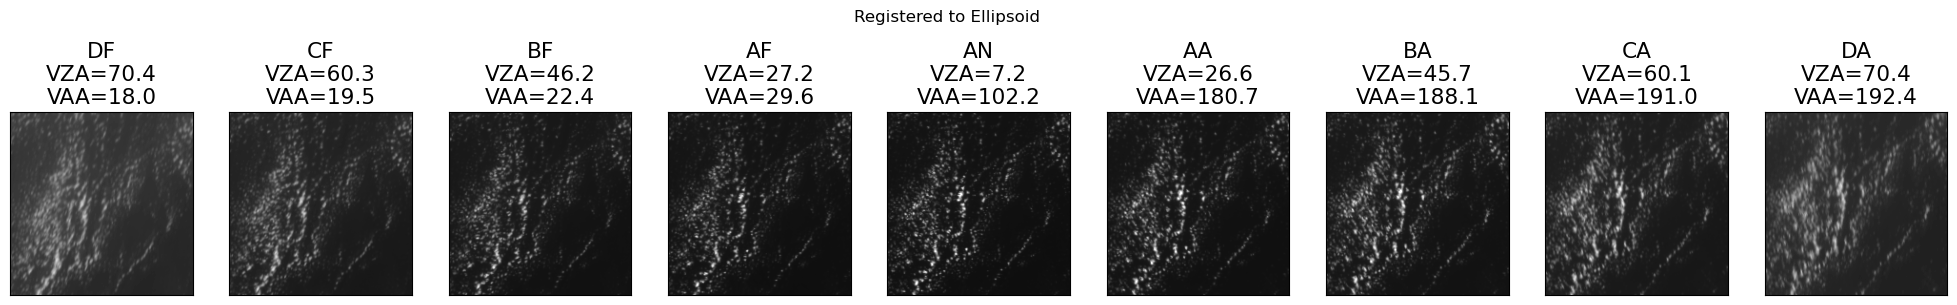

In [4]:
fig, ax = plt.subplots(1, 9, figsize=(25, 4))
plot_misr_data(misr_data_file, fig, ax, vmax=0.5, cbar_loc=None)

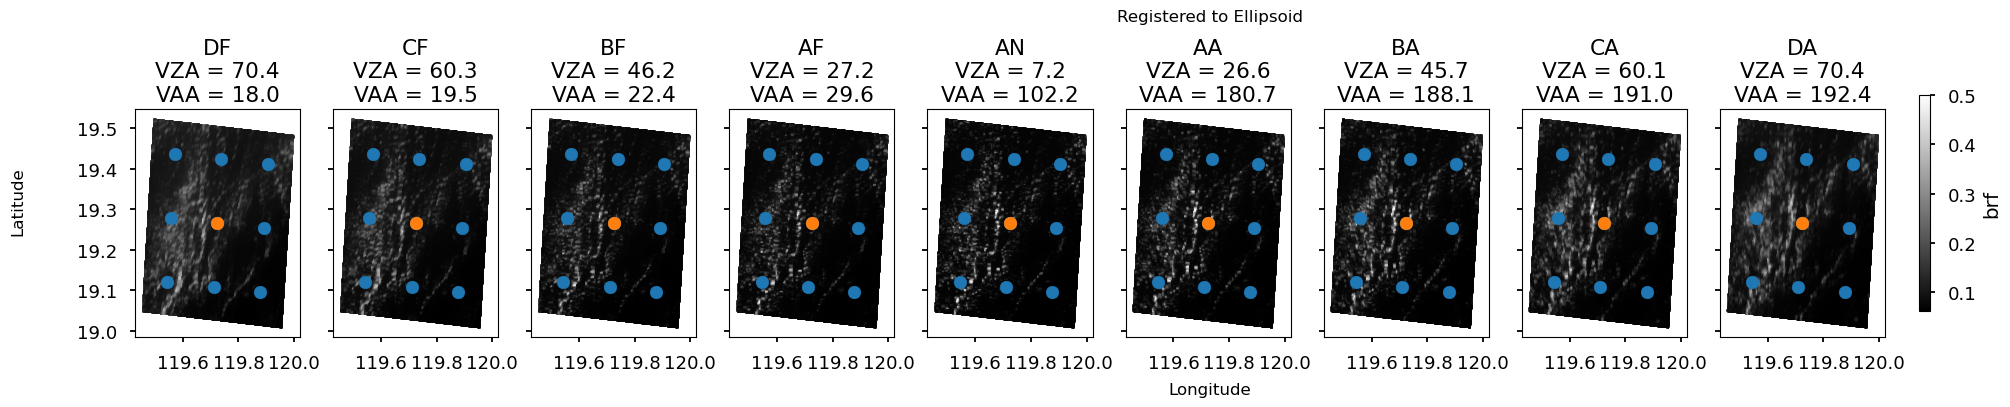

In [5]:
fig, ax = plt.subplots(1, 9, figsize=(25, 4), sharex=True, sharey=True)
plot_misr_data_map(misr_data_file, fig, ax, vmax=0.5, cbar_loc='right', s=2.0)
overlay_sampling(misr_data_file, fig, ax)
fig.subplots_adjust(top=0.73, bottom=0.16, left=0.07, right=0.77)

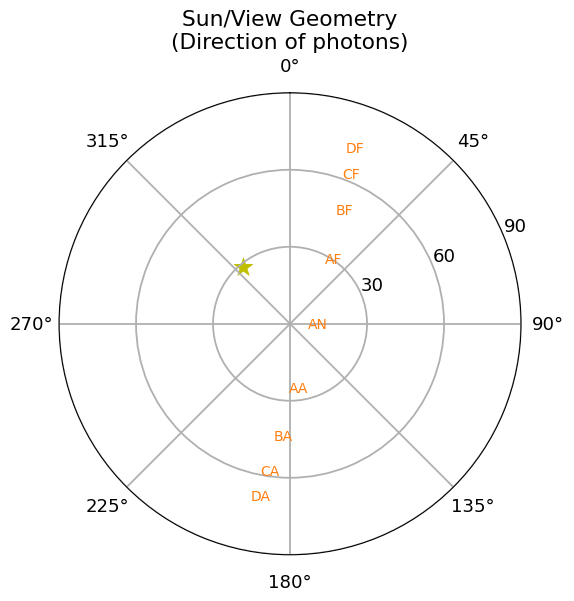

In [6]:
f, ax = plt.subplots(1, 1, figsize = (6, 6), subplot_kw={'projection': 'polar'})
plot_sun_view_grometry(misr_data_file, ax)

# Preprocess 2 plots

In [7]:
import netCDF4 as nc
import at3d
import glob
import imageio.v2 as imageio
import os

In [8]:
measurements_file = '../dev/measurements.nc'

In [9]:
def load_measurements(file_name):
    """
    Load from netCDF the sensors that were saved using 'save_forward_model'
    above. Adapted from at3d.util.load_forward_model.
    """
    dataset = nc.Dataset(file_name)

    groups = dataset.groups
    sensors = groups['sensors'].groups
    sensor_dict = at3d.containers.SensorsDict()

    for key, sensor in sensors.items():
        sensor_list = []
        for i, image in sensor.groups.items():
            sensor_dataset = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset[
                'sensors/{}/{}'.format(key, i)]))
            sensor_dataset['stokes'] = (['stokes_index'],sensor_dataset['stokes'].data.astype(bool))
            sensor_dataset['use_subpixel_rays'] = sensor_dataset['use_subpixel_rays'].data.astype(bool)
            sensor_dict.add_sensor(key, sensor_dataset)
    return sensor_dict

def plot_measurements(filename, instrument, fig, ax, s=2):
    sensor_dict = load_measurements(filename)
    sensor_list = sensor_dict[instrument]['sensor_list']
    for i, cam in enumerate(sensor_list):
        z = np.unique(cam.ray_z.data)
        if(len(z) == 1):
            title = '{}\nz={} km'.format(cam.name, z[0])
        else:
            title = '{}\nz=non-uniform'.format(cam.name)
        ax[i].scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray')
        ax[i].set_title(title)

def make_movie(dir, outfile, nframes=None, fps=3):
    images = []
    files = np.sort(glob.glob(dir + '*.png'))
    if nframes != None:
        for i in range(nframes):
            fi = files[i]
            images.append(imageio.imread(fi))
        for i in range(nframes-2, 0, -1):
            fi = files[i]
            images.append(imageio.imread(fi))
    else:
        for fi in files:
           images.append(imageio.imread(fi))
    imageio.mimsave(outfile, images, loop=15, duration=3, fps=fps)

def measurements_to_gif(filename, instrument, dir, outfile, s=2):
    sensor_dict = load_measurements(filename)
    sensor_list = sensor_dict[instrument]['sensor_list']
    os.makedirs(dir, exist_ok=False)
    for i, cam in enumerate(sensor_list):
        z = np.unique(cam.ray_z.data)
        f, ax = plt.subplots(1, 1, figsize = (5, 5))
        ax.scatter(cam.ray_x.data, cam.ray_y.data, s=s, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray')
        ax.set_xlim([-5, 24])
        ax.set_ylim([-11, 28])
        if(len(z) == 1):
            title = '{}\nz={} km'.format(cam.name, z[0])
        else:
            title = '{}\nz=non-uniform'.format(cam.name)
        ax.set_title(title)
        f.savefig('{}frame{:03d}.png'.format(dir, i))
        plt.close(f)
    make_movie(dir, outfile, nframes=len(sensor_list), fps=10)

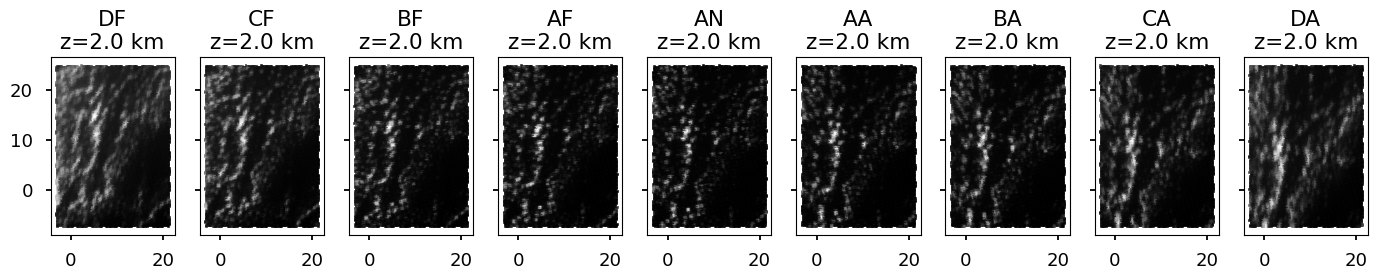

In [10]:
fig, ax = plt.subplots(1, 9, figsize=(17, 2.3), sharex=True, sharey=True)
plot_measurements(measurements_file, 'MISR', fig, ax, s=2)

In [12]:
dir = '../dev/measurement_movie/'
outfile = '{}movie.gif'.format(dir)
measurements_to_gif(measurements_file, 'MISR', dir=dir, outfile=outfile, s=10)